# Navier-Stokes in C#: dalle domande di tutti i giorni alla simulazione

Data science e calcolo scientifico **non solo in Python**: qui tutto è C# e .NET, senza librerie esterne.
Simulatori, grafici SVG e persino l'encoder PNG sono scritti a mano nella libreria `NavierStokes.Core`.

## Le equazioni, spiegate semplici

Le equazioni di Navier-Stokes sono la **F = m·a dei fluidi**. Per ogni "goccia" d'aria o d'acqua dicono:

$$\rho\left(\frac{\partial \mathbf{u}}{\partial t} + \mathbf{u}\cdot\nabla\mathbf{u}\right) = -\nabla p + \mu\,\nabla^2\mathbf{u} + \mathbf{f} \qquad \nabla\cdot\mathbf{u} = 0$$

| Termine | Significato | Esempio |
|---|---|---|
| $\rho\,(\partial_t \mathbf{u} + \mathbf{u}\cdot\nabla\mathbf{u})$ | inerzia: massa × accelerazione | l'aria in moto tende a continuare a muoversi |
| $-\nabla p$ | la pressione spinge da dove è alta a dove è bassa | il vento va dall'alta alla bassa pressione |
| $\mu\,\nabla^2\mathbf{u}$ | viscosità: attrito interno tra strati vicini | il miele scorre lento, l'acqua no |
| $\mathbf{f}$ | forze esterne | gravità, una ventola, una pompa |
| $\nabla\cdot\mathbf{u}=0$ | quello che entra esce | l'acqua non si comprime |

**Esempio per tutti:** un quadro elettrico con una ventola che soffia lungo il lato superiore.
L'aria sotto viene trascinata e gira in un grande vortice, ma negli angoli resta quasi ferma: lì i componenti scaldano.
È proprio il primo problema che risolviamo.

> Prima di eseguire: `dotnet build -c Release` nella cartella della soluzione. Il notebook usa un kernel C#
> (.NET Interactive / Polyglot Notebooks); le celle sono puro C#, quindi funzionano anche copiate in un'app console.

In [1]:
#r "../src/NavierStokes.Core/bin/Release/net11.0/NavierStokes.Core.dll"
using NavierStokes.Core;

## Il numero che decide tutto: Reynolds

$Re = \dfrac{U \cdot L}{\nu}$: inerzia contro attrito. Sotto qualche migliaio il flusso è ordinato (laminare),
sopra diventa turbolento. Ecco qualche caso quotidiano:

In [2]:
var casi = new (string Cosa, double Velocita, double Dimensione, Fluid Fluido)[]
{
    ("Miele che cola dal cucchiaio",       0.01,  0.01,  new Fluid("Miele", 1420, 7e-3)),
    ("Acqua nel tubo del giardino",        1.4,   0.025, Fluid.Water),
    ("Aria nel quadro elettrico (ventola)", 1.5,  0.8,   Fluid.Air),
    ("Vento su un palo della luce",        11,    0.12,  Fluid.Air),
    ("Aria attorno a un'auto in autostrada", 36,  1.8,   Fluid.Air),
};
foreach (var c in casi)
{
    double re = Flow.Reynolds(c.Velocita, c.Dimensione, c.Fluido);
    string reText = re < 10 ? re.ToString("0.00") : re.ToString("N0");
    Console.WriteLine($"{c.Cosa,-38} Re = {reText,12}   {Flow.Regime(re)}");
}

Miele che cola dal cucchiaio           Re =         0.01   laminare (ordinato, a strati)
Acqua nel tubo del giardino            Re =       34,861   turbolento (vortici e mescolamento)
Aria nel quadro elettrico (ventola)    Re =       79,156   turbolento (vortici e mescolamento)
Vento su un palo della luce            Re =       87,071   turbolento (vortici e mescolamento)
Aria attorno a un'auto in autostrada   Re =    4,274,406   turbolento (vortici e mescolamento)


## 1. Il quadro elettrico: la cavità con coperchio mobile

Risolviamo Navier-Stokes 2D con differenze finite e metodo di proiezione: a ogni passo si calcola la pressione
che rende il campo a divergenza nulla, poi si aggiorna la velocità. Usiamo Re = 100 perché esiste un benchmark
classico con cui confrontarci: Ghia, Ghia & Shin (1982).

In [3]:
var cavita = new CavitySolver(n: 81, reynolds: 100);
var sw = System.Diagnostics.Stopwatch.StartNew();
cavita.Run();
Console.WriteLine($"Regime raggiunto in {cavita.Step:N0} passi, t = {cavita.Time:0.0}, {sw.Elapsed.TotalSeconds:0} s di calcolo");
Console.WriteLine($"Divergenza RMS (dovrebbe essere ~0): {cavita.RmsDivergence():0.0e0}");

Regime raggiunto in 8,874 passi, t = 22.2, 18 s di calcolo
Divergenza RMS (dovrebbe essere ~0): 2.4e-2


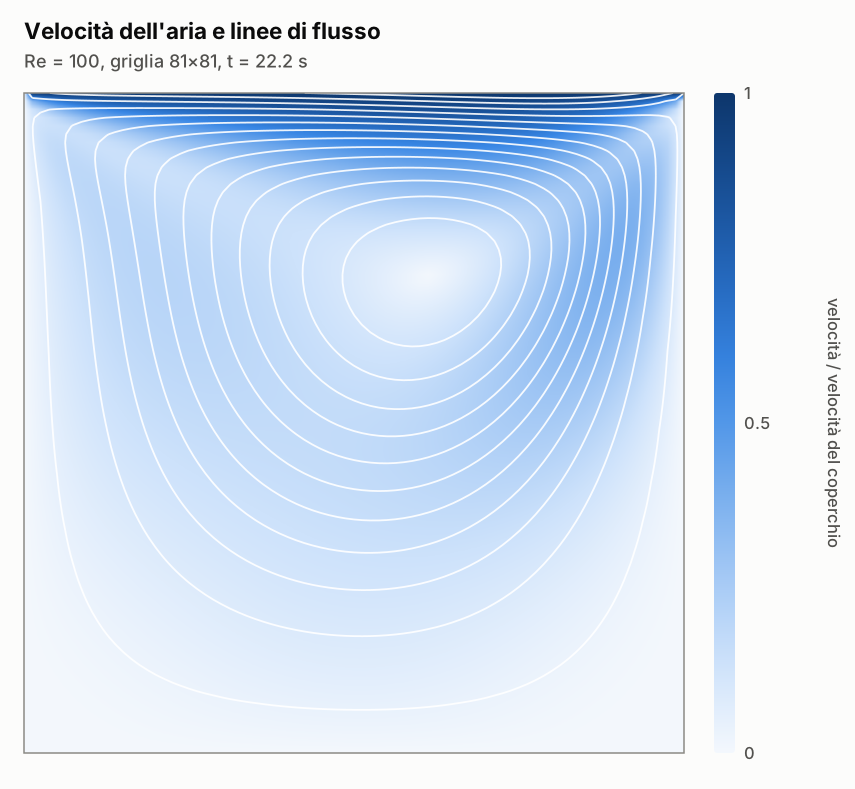

In [4]:
display(HTML(Reports.CavityVelocity(cavita)));

Le linee bianche sono le **linee di flusso**: le curve di livello della funzione di corrente $\psi$, tracciate con
un marching squares scritto a mano. Il vortice principale è spostato verso il coperchio; in basso, negli angoli,
la velocità è quasi zero.

### Funziona davvero? Confronto con il benchmark

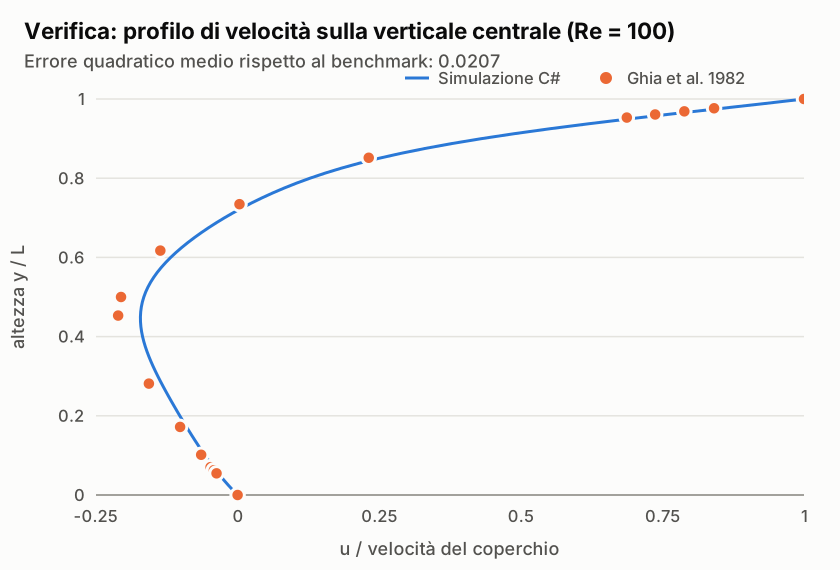

In [5]:
display(HTML(Reports.CavityGhia(cavita)));

Il profilo di velocità sulla verticale centrale segue i dati di riferimento, con un errore quadratico medio di circa 0,02.
Lo scarto più visibile è al centro del vortice, dove la griglia 81×81 e lo schema semplice sottostimano un po'
il picco negativo: è il prezzo di un codice didattico di poche centinaia di righe.

### Pressione e direzione del flusso

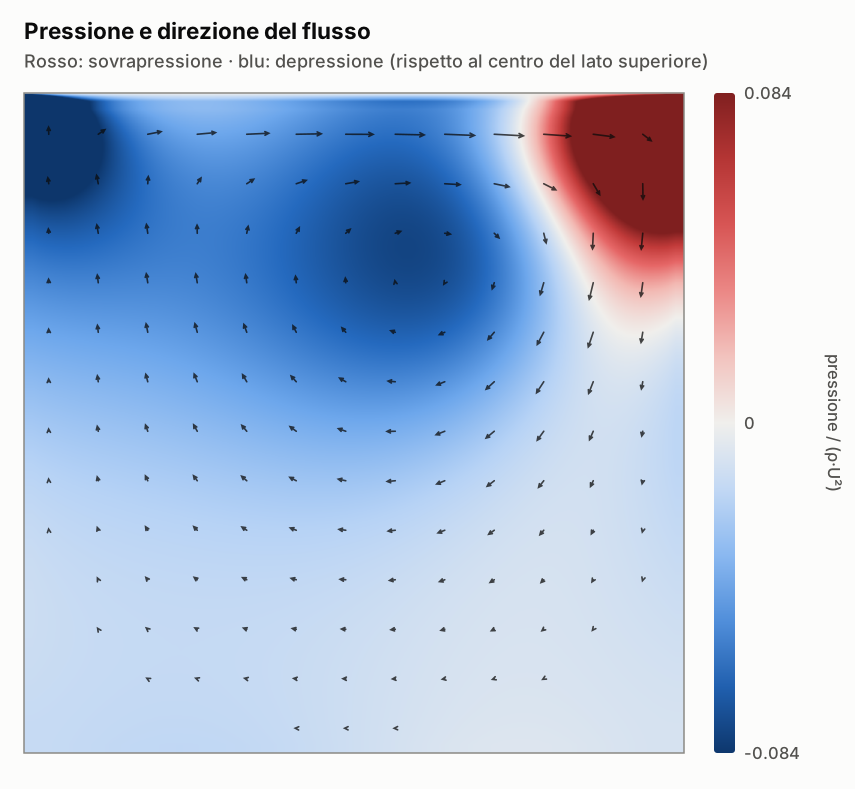

In [6]:
display(HTML(Reports.CavityPressure(cavita)));

Nell'angolo in alto a destra l'aria trascinata dal coperchio sbatte contro la parete: sovrapressione (rosso).
Al centro del vortice e nell'angolo in alto a sinistra c'è depressione (blu).

### Una time series: l'energia cinetica nel tempo

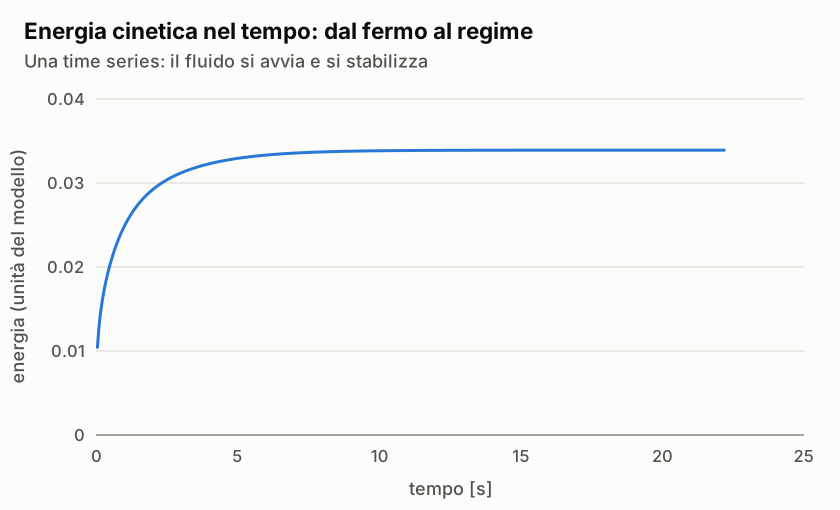

In [7]:
display(HTML(Reports.CavityEnergy(cavita)));

## 2. Il cavo che fischia: la scia di von Kármán

Qui usiamo un altro metodo, **Lattice Boltzmann**: si muovono "pacchetti" di particelle su una griglia, e su larga
scala il loro comportamento medio obbedisce a Navier-Stokes. I vortici si staccano alternati con frequenza
$f = St \cdot U / D$, dove il numero di Strouhal $St \approx 0{,}2$.

Strouhal misurato: St = 0.188


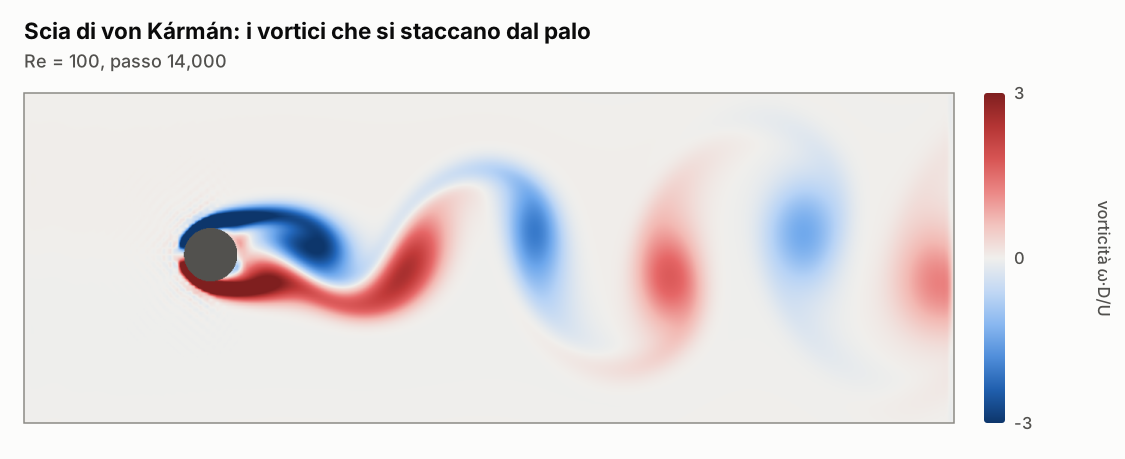

In [8]:
var palo = new CylinderLbm(reynolds: 100);
palo.Run(14000);
Console.WriteLine($"Strouhal misurato: St = {palo.Strouhal():0.000}");
display(HTML(Reports.CylinderVorticity(palo)));

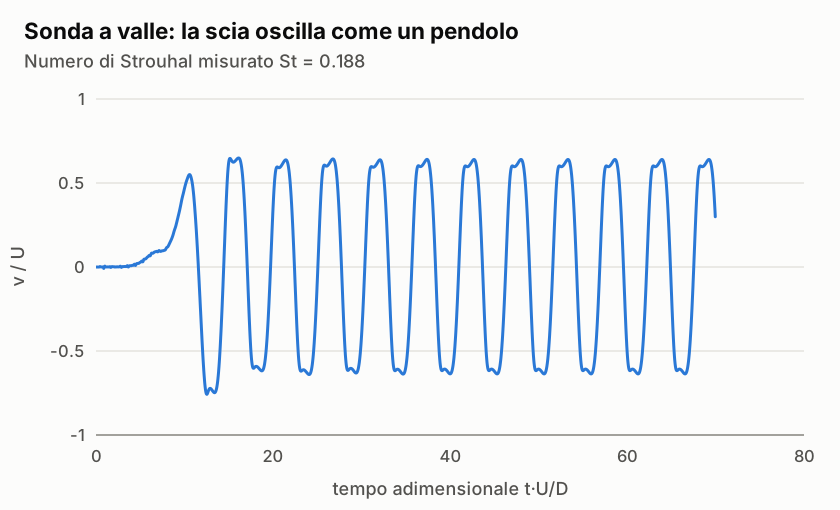

In [9]:
display(HTML(Reports.CylinderProbe(palo)));

In [10]:
// Dalla simulazione al mondo reale: un conduttore di linea elettrica da 28 mm con vento a 40 km/h
double vento = 40 / 3.6, diametro = 0.028;
double f = VortexShedding.Frequency(vento, diametro);
Console.WriteLine($"Frequenza di distacco: {f:0} Hz → nota {VortexShedding.MusicalNote(f)}");

Frequenza di distacco: 79 Hz → nota Re♯ (ottava 2)


Il St misurato è un po' più alto del valore di letteratura a Re 100 (circa 0,165) perché il canale simulato è stretto
e "confina" la scia. A Reynolds reali, da qualche centinaio fino a circa 200.000, St resta vicino a 0,2.

## 3. Due risposte rapide: tubo e vento

Non tutte le domande richiedono una simulazione. In un tubo in regime laminare Navier-Stokes ha una soluzione esatta
(Hagen-Poiseuille); in turbolento usiamo formule tarate su esperimenti e simulazioni delle stesse equazioni.

In [11]:
var tubo = Pipe.Solve(Fluid.Water, diameterM: 0.025, lengthM: 50, flowLpm: 40, roughnessMm: 0.0015);
Console.WriteLine($"Velocità {tubo.MeanSpeed:0.00} m/s, Re {tubo.Reynolds:N0} ({tubo.Regime})");
Console.WriteLine($"Perdita di pressione: {tubo.PressureDropPa / 1e5:0.00} bar");

double forza = Wind.Force(90 / 3.6, areaM2: 2, Shape.FlatPlate);
Console.WriteLine($"Vento a 90 km/h su un pannello da 2 m²: {forza:N0} N, come appoggiarci {forza / 9.81:N0} kg");

Velocità 1.36 m/s, Re 33,818 (turbolento (vortici e mescolamento))
Perdita di pressione: 0.42 bar
Vento a 90 km/h su un pannello da 2 m²: 963 N, come appoggiarci 98 kg


## E la dimostrazione dell'AI?

Queste equazioni funzionano: lo dimostrano due secoli di ingegneria e i grafici qui sopra. La domanda matematica aperta
era se le soluzioni restano sempre lisce o se, in qualche caso estremo, sviluppano una velocità infinita in tempo finito.
La dimostrazione annunciata nel 2026 sostiene la seconda ipotesi ed è ancora al vaglio dei matematici.
Non dice che le equazioni siano sbagliate: indica dove il modello del fluido come continuo, senza molecole, smette di bastare.
Un po' come Newton, che resta perfetto finché non servono la velocità della luce o la precisione di un GPS.